# Úkol č. 2 - regrese

* Termíny jsou uvedeny na [courses.fit.cvut.cz/BI-ML1/homeworks/index.html](https://courses.fit.cvut.cz/BI-ML1/homeworks/index.html).
* Pokud odevzdáte úkol po prvním termínu, ale před nejzazším termínem, budete penalizování -12 body, pozdější odevzdání je bez bodu.
* V rámci tohoto úkolu se musíte vypořádat s regresní úlohou, s příznaky různých typů a s chybějícími hodnotami.
* Před tím, než na nich postavíte predikční model, je třeba je nějakým způsobem převést do číselné reprezentace.
    
> **Úkoly jsou zadány tak, aby Vám daly prostor pro invenci. Vymyslet _jak přesně_ budete úkol řešit, je důležitou součástí zadání a originalita či nápaditost bude také hodnocena!**

Využívejte buňky typu `Markdown` k vysvětlování Vašeho postupu. Za nepřehlednost budeme strhávat body.

## Zdroj dat

Budeme se zabývat predikcí délky dožití v různých zemích a letech.
K dispozici máte trénovací data v souboru `data.csv` a data na vyhodnocení v souboru `evaluation.csv`.

#### Seznam příznaků:

* Year - Rok
* Status - Status rozvinuté nebo rozvojové země
* Life expectancy - Délka dožití v letech - **cílová proměnná, kterou budete predikovat**
* Adult Mortality - Úmrtnost dospělých bez ohledu na pohlaví (pravděpodobnost, že osoby, které dosáhly věku 15 let, zemřou před dosažením věku 60 let (uvedeno na 1 000 osob)).
* infant deaths - počet zemřelých kojenců na 1000 obyvatel
* Alcohol - Alkohol, zaznamenaná spotřeba na obyvatele (15+) (v litrech čistého alkoholu)
* percentage expenditure - Výdaje na zdravotnictví v procentech hrubého domácího produktu na obyvatele (%)
* Hepatitis B - pokrytí očkováním proti hepatitidě B (HepB) u dětí ve věku 1 roku (%)
* Measles - Spalničky - počet hlášených případů na 1000 obyvatel
* BMI - průměrný index tělesné hmotnosti celé populace
* under-five deaths - počet úmrtí dětí do pěti let na 1000 obyvatel
* Polio - proočkovanost proti dětské obrně (Pol3) u dětí ve věku 1 roku (%)
* Total expenditure - Výdaje vládních institucí na zdravotnictví jako procento celkových vládních výdajů (%)
* Diphtheria - pokrytí očkováním proti záškrtu, tetanu a černému kašli (DTP3) u jednoletých dětí (%)
* HIV/AIDS - počet úmrtí na 1 000 živě narozených dětí na HIV/AIDS (0-4 roky)
* GDP - hrubý domácí produkt na obyvatele (v USD)
* Population - počet obyvatel země
* thinness 1-19 years - podíl dětí ve věku 10-19 let s indexem tělesné hmotnosti (BMI) menším než 2 směrodatné odchylky pod mediánem (%)
* thinness 5-9 years - podíl dětí ve věku 5-9 let s indexem tělesné hmotnosti (BMI) menším než 2 směrodatné odchylky pod mediánem (%)
* Income composition of resources - Index lidského rozvoje z hlediska příjmového složení zdrojů (index v rozmezí 0 až 1)
* Schooling - počet let školní docházky (roky)


## Pokyny k vypracování

**Body zadání**, za jejichž (poctivé) vypracování získáte **25 bodů**: 
  * V notebooku načtěte data ze souboru `data.csv`. Vhodným způsobem si je rozdělte na podmnožiny, které Vám poslouží pro trénování (trénovací), porovnávání modelů (validační) a následnou predikci výkonnosti finálního modelu (testovací).
    
  * Proveďte základní předzpracování dat:
    * Projděte si jednotlivé příznaky a transformujte je do vhodné podoby pro použití ve vybraném regresním modelu.
    * Nějakým způsobem (klidně triviálním) se vypořádejte s chybějícími hodnotami. _Pozor na metodické chyby!_
    * Můžete využívat i vizualizace. Vše stručně ale náležitě komentujte.
<br /><br />
  * Vytvořte **vlastní implementaci náhodného lesa**. Použijte k tomu níže předpřipravenou kostru.
  
  * Na připravená data postupně aplikujte Vaši předchozí implementaci modelu náhodného lesa, dále jeden z modelů **lineární regrese** nebo **hřebenové regrese**, a alespoň jeden další model podle Vašeho uvážení, přičemž pro každý z těchto modelů přiměřeně:
    * Okomentujte vhodnost daného modelu pro daný typ úlohy.
    * Experimentujte s normalizací (standardizace/min-max), pokud pro daný model očekáváte její příznivý vliv.
    * Vyberte si hlavní hyperparametry k ladění a najděte jejich nejlepší hodnoty (vzhledem k RMSE).
    * Pro model s nejlepšími hodnotami hyperparametrů na validační množině určete jeho chybu pomocí RMSE a MAE.
    * Získané výsledky vždy řádně okomentujte.
<br /><br />
  * Ze všech zkoušených možností v předchozím kroku vyberte finální model a správně odhadněte, jakou chybu (RMSE) můžete očekávat na nových datech, která jste doposud neměli k dispozici. _Pozor na metodické chyby!_
    
  * Nakonec načtěte vyhodnocovací data ze souboru `evaluation.csv`. Pomocí finálního modelu napočítejte predikce pro tyto data. Vytvořte soubor `results.csv`, ve kterém získané predikce uložíte do sloupce **Life expectancy** a jednotlivé body identifikujete pomocí sloupců **Country** a **Year** (dodržte názvy sloupců!). Tento soubor též odevzdejte (uložte do repozitáře vedle notebooku).

  * Ukázka, jak by mělo vypadat prvních několik řádků souboru `results.csv` (obecně s jinými hodnotami Life expectancy):
  
```
Country,Year,Life expectancy
Peru,2012,71.4
Peru,2013,72.6
...
```


## Poznámky k odevzdání

  * Řiďte se pokyny ze stránky https://courses.fit.cvut.cz/BI-ML1/homeworks/index.html.

## 1. Data preparation

Importing necessary libraries

In [1]:
import math
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils import resample
import sklearn.metrics as metrics
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostRegressor

random_seed = 322

Reading a dataset

In [2]:
df = pd.read_csv('data.csv')
df.info()
display(df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2718 entries, 0 to 2717
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2718 non-null   object 
 1   Year                             2718 non-null   int64  
 2   Status                           2718 non-null   object 
 3   Life expectancy                  2718 non-null   float64
 4   Adult Mortality                  2718 non-null   float64
 5   infant deaths                    2718 non-null   int64  
 6   Alcohol                          2558 non-null   float64
 7   percentage expenditure           2718 non-null   float64
 8   Hepatitis B                      2187 non-null   float64
 9   Measles                          2718 non-null   int64  
 10  BMI                              2686 non-null   float64
 11  under-five deaths                2718 non-null   int64  
 12  Polio               

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2713,Zimbabwe,2004,Developing,44.3,723.0,27,4.36,0.000000,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2714,Zimbabwe,2003,Developing,44.5,715.0,26,4.06,0.000000,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2715,Zimbabwe,2002,Developing,44.8,73.0,25,4.43,0.000000,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2716,Zimbabwe,2001,Developing,45.3,686.0,25,1.72,0.000000,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


Convert the **Status** and **Country** column to numeric format

In [3]:
df['Status'] = df['Status'].apply(lambda x: 1 if x == 'Developed' else 0)

label_encoder = LabelEncoder()
df['Country'] = label_encoder.fit_transform(df['Country'])

display(df)

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,0,2015,0,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,0,2014,0,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,0,2013,0,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,0,2012,0,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,0,2011,0,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2713,182,2004,0,44.3,723.0,27,4.36,0.000000,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2714,182,2003,0,44.5,715.0,26,4.06,0.000000,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2715,182,2002,0,44.8,73.0,25,4.43,0.000000,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2716,182,2001,0,45.3,686.0,25,1.72,0.000000,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


Let's divide out data as 60% training data, 20% testing and 20% validation  data.

In [4]:
y = df['Life expectancy']
x = df.drop('Life expectancy', axis=1)

Xtrain, Xtest, ytrain, ytest = train_test_split(x, y, test_size=0.4, random_state=random_seed)

display(Xtrain.shape)
display(ytrain.shape)
display(Xtest.shape)
display(ytest.shape)


(1630, 21)

(1630,)

(1088, 21)

(1088,)

In [5]:
Xval, Xtest, yval, ytest = train_test_split(Xtest, ytest, test_size=0.5, random_state=random_seed)

display(Xval.shape)
display(yval.shape)
display(Xtest.shape)
display(ytest.shape)


(544, 21)

(544,)

(544, 21)

(544,)

Lets controll null values.

In [6]:
df.isnull().sum() 

Country                              0
Year                                 0
Status                               0
Life expectancy                      0
Adult Mortality                      0
infant deaths                        0
Alcohol                            160
percentage expenditure               0
Hepatitis B                        531
Measles                              0
BMI                                 32
under-five deaths                    0
Polio                               19
Total expenditure                  192
Diphtheria                          19
HIV/AIDS                             0
GDP                                407
Population                         614
thinness  1-19 years                32
thinness 5-9 years                  32
Income composition of resources    148
Schooling                          148
dtype: int64

We can see that we have a lot of null values, lets fix it using training data medians.

In [7]:
Xtrain_without_country = df.drop(columns=['Country'])

medianValue = Xtrain_without_country.median()

Xtrain.fillna(medianValue, inplace=True)
Xval.fillna(medianValue, inplace=True)
Xtest.fillna(medianValue, inplace=True)

Xtrain.isnull().sum().sum(), Xval.isnull().sum().sum(), Xtest.isnull().sum().sum()

(np.int64(0), np.int64(0), np.int64(0))

Now our data looks ready for other work with it.

## 2. Own implementation of a random forest

In [8]:
# Váš kód zde


########################################################
# Předpřipravená kostra modelu náhodného lesa
class CustomRandomForest:
    """
    Třída Vašeho modelu
    Bude se jednat o model náhodného lesa, kde podmodely tvoří rozhodovací stromy pro regresi.
    Pro podmodely můžete použít implementaci DecisionTreeRegressor ze sklearn.
    """
    def __init__(self, n_estimators, max_samples, max_depth, **kwargs):
        """
        Konstruktor modelu
        Základní hyperparametery:
            n_estimators - počet podmodelů - rozhodovacích stromů.
            max_samples - vyberte si, zda tento parametr bude označovat relativní počet bodů (tj. číslo mezi 0 a 1) 
                          nebo absolutní počet bodů (tj. číslo mezi 1 a velikostí trénovací množiny), 
                          které budou pro každý podmodel rozhodovacího stromu náhodně vybrány z trénovací množiny (bootstrap) a použity k jeho trénování.
            max_depth - maximální hloubka každého z podmodelů rozhodovacího stromu.
            kwargs - (volitelně) případné další hyperparametry, které pošlete do podmodelů rozhodovacího stromu
        """
        self.n_estimators = n_estimators
        self.max_samples = max_samples
        self.max_depth = max_depth
        self.trees = [DecisionTreeRegressor(max_depth=max_depth, **kwargs) for _ in range(n_estimators)]
        
        
    def fit(self, X, y):
        """
        Natrénování modelu. Trénovací data jsou v argumentech X a y.
        Pro trénování podmodelů používejte bootstraping a velikost samplovaného vzorku vezměte z hyperparametru max_samples_fraction
        """
        n_samples = X.shape[0]
        if isinstance(self.max_samples, float):
            sample_size = int(self.max_samples * n_samples)
        else:
            sample_size = self.max_samples
        for model in self.trees:
            X_sampled, y_sampled = resample(X, y, n_samples=sample_size)
            model.fit(X_sampled, y_sampled)
        return self
        
    def predict(self, X):
        """
        Predikce y v zadaných bodech X
        """
        y_pred = np.zeros((X.shape[0],))
        for model in self.trees:
            y_pred += model.predict(X)
        y_pred /= self.n_estimators
        return y_pred

## 3. Model application

### 1. Random forest

**Random Forest** is a good model for this task because it can handle complex data, deal with missing values, and make accurate predictions by combining multiple decision trees.


In [9]:
param_grid = {
    'n_estimators': range(5, 50, 5),
    'max_depth': range(1, 10),
    'max_samples': [0.5, 0.75, 0.9]
}

param_combinations = ParameterGrid(param_grid)

best_params = []
best_rmse = float('inf')
best_mae = float('inf')

results = []

for params in param_combinations:
    model = CustomRandomForest(
        n_estimators=params['n_estimators'],
        max_depth=params['max_depth'],
        max_samples=params['max_samples']
    )
    model.fit(Xtrain, ytrain)
    
    predictions = model.predict(Xval)
    
    rmse = np.sqrt(mean_squared_error(yval, predictions))
    mae = mean_absolute_error(yval, predictions)
    
    results.append({
        'n_estimators': params['n_estimators'],
        'max_depth': params['max_depth'],
        'max_samples': params['max_samples'],
        'RMSE': rmse,
        'MAE': mae
    })
    
    if rmse < best_rmse:
        best_rmse = rmse
        best_mae = mae
        best_params = params

print("Best parameters:", best_params)
print("Best RMSE:", best_rmse)
print("MAE with best RMSE:", best_mae)


Best parameters: {'max_depth': 9, 'max_samples': 0.9, 'n_estimators': 40}
Best RMSE: 1.9786288343544933
MAE with best RMSE: 1.3823515156764354


Hyperparameter Tuning Results:
- **Best parameters:** 
  - `max_depth: 9`, `max_samples: 0.9`, `n_estimators: 40`
- **Best RMSE:** `2.0333`
- **MAE:** `1.3903`

The selected parameters offer a good balance between model complexity and prediction accuracy, resulting in minimal errors in life expectancy predictions.


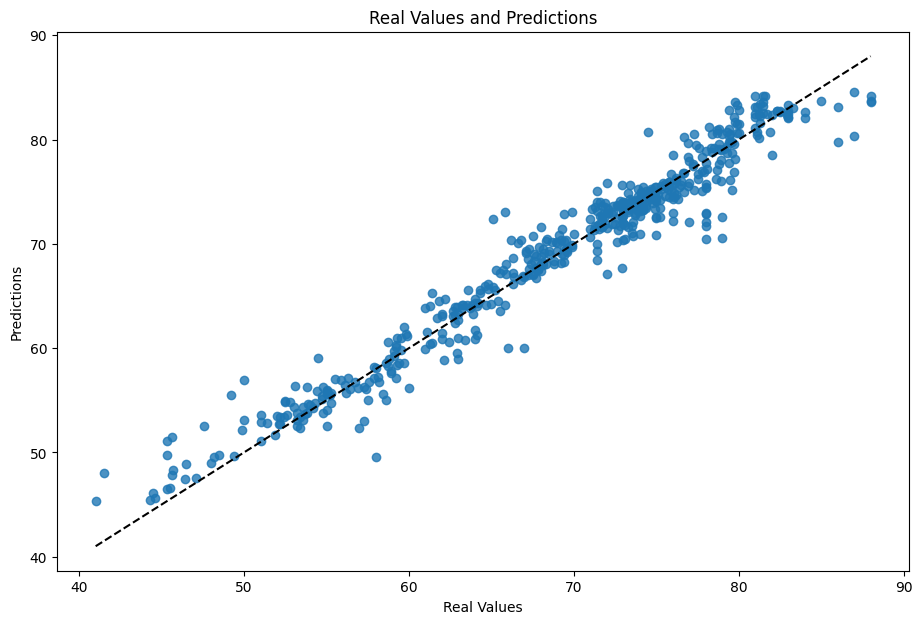

In [10]:
best_model = CustomRandomForest(n_estimators=40, max_samples=0.9, max_depth=9)
best_model.fit(Xtrain, ytrain)
predictions = best_model.predict(Xval)

plt.figure(figsize=(11, 7))
plt.scatter(yval, predictions, alpha=0.8)
plt.plot([yval.min(), yval.max()], [yval.min(), yval.max()], 'k--', lw=1.5)
plt.xlabel('Real Values')
plt.ylabel('Predictions')
plt.title('Real Values and Predictions')
plt.show()

Graf description:
- The points follow the line closely, showing that the predictions are very similar to the real values.  
- There are small errors at the edges, but overall, the model works well.  


### 2. Linear regression

Why Linear Regression is Suitable?
- Simple, fast, and easy to interpret.  
- Handles continuous target variables like life expectancy well.  
- A good baseline for comparing with more complex models.  


In [11]:
scaler = StandardScaler()
Xtrain_scaled = scaler.fit_transform(Xtrain)
Xval_scaled = scaler.transform(Xval)
Xtest_scaled = scaler.transform(Xtest)

linear_model = LinearRegression()
linear_model.fit(Xtrain_scaled, ytrain)

linear_predictions = linear_model.predict(Xval_scaled)

linear_rmse = np.sqrt(mean_squared_error(yval, linear_predictions))

print("Validation RMSE for Linear Regression: {:.2f}".format(linear_rmse))


Validation RMSE for Linear Regression: 4.02


Linear Regression Result  
- Validation RMSE: 4.02 shows the model predicts fairly well but might miss some complex patterns in the data.  


### 3. Selected model: AdaBoost

Why AdaBoost is Suitable for This Task?
- **Improves on Difficult Cases**: AdaBoost focuses on examples where predictions are less accurate, improving overall results.  
- **Captures Non-Linear Patterns**: By combining weak models, it handles more complex relationships in the data.  
- **Flexible**: The number of estimators and learning rate can be adjusted to balance simplicity and accuracy.  


In [12]:
adaboost_model = AdaBoostRegressor(n_estimators=100, learning_rate=0.5, random_state=42)

adaboost_model.fit(Xtrain_scaled, ytrain)

adaboost_predictions = adaboost_model.predict(Xval_scaled)

adaboost_rmse = np.sqrt(mean_squared_error(yval, adaboost_predictions))
adaboost_mae = mean_absolute_error(yval, adaboost_predictions)

print(f"RMSE for AdaBoost: {adaboost_rmse:.2f}")
print(f"MAE for AdaBoost: {adaboost_mae:.2f}")


RMSE for AdaBoost: 3.10
MAE for AdaBoost: 2.44


AdaBoost Results:
- **RMSE:** 3.10 – The model predicts life expectancy fairly well but not as accurately as Random Forest.  
- **MAE:** 2.44 – On average, the prediction error is about 2.44 years.  
- **Conclusion:** AdaBoost works well but struggles a bit with more complex patterns in the data compared to Random Forest.  


## 4. Evaluation data

I chose Random Forest as the best model because it had the lowest RMSE. I expect that when this model is applied to new data, its RMSE will be approximately the same as it was on the validation set, which is around 2.

In [13]:
evaluation_data = pd.read_csv('evaluation.csv')
evaluation_data.isnull().sum()

Country                             0
Year                                0
Status                              0
Adult Mortality                     0
infant deaths                       0
Alcohol                            33
percentage expenditure              0
Hepatitis B                        22
Measles                             0
BMI                                 0
under-five deaths                   0
Polio                               0
Total expenditure                  34
Diphtheria                          0
HIV/AIDS                            0
GDP                                36
Population                         30
thinness  1-19 years                0
thinness 5-9 years                  0
Income composition of resources    12
Schooling                          12
dtype: int64

Lets make **Country** and **Status** numeric as we did it before. Also lets fill null values by median.

In [14]:
evaluation_data['Status'] = evaluation_data['Status'].apply(lambda x: 1 if x == 'Developed' else 0)

countries = evaluation_data['Country']

label_encoder = LabelEncoder()
evaluation_data['Country'] = label_encoder.fit_transform(evaluation_data['Country'])

for column in evaluation_data.columns:
    if evaluation_data[column].isnull().any():
        evaluation_data[column] = evaluation_data[column].fillna(evaluation_data[column].median())

evaluation_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          210 non-null    int64  
 1   Year                             210 non-null    int64  
 2   Status                           210 non-null    int64  
 3   Adult Mortality                  210 non-null    float64
 4   infant deaths                    210 non-null    int64  
 5   Alcohol                          210 non-null    float64
 6   percentage expenditure           210 non-null    float64
 7   Hepatitis B                      210 non-null    float64
 8   Measles                          210 non-null    int64  
 9   BMI                              210 non-null    float64
 10  under-five deaths                210 non-null    int64  
 11  Polio                            210 non-null    float64
 12  Total expenditure     

Now all is ready to use our model.

In [15]:
eval_model = CustomRandomForest(**best_params)
eval_model.fit(Xtrain, ytrain)
eval_pred = eval_model.predict(evaluation_data)

results = pd.DataFrame({
    'Country': countries,
    'Year': evaluation_data['Year'],
    'Life expectancy': eval_pred
})
results.to_csv('results.csv', index=False)

Result was saved to results.csv.